# Procesamiento del CEM 4.0

**Pregunta del proyecto:** ¿hay más socavones en las colonias con alta frecuencia de inundaciones que en las de baja (Guadalajara y Zapopan, 2020–2024)?

El procesamiento de imágenes se usa para obtener la **topografía de cada colonia** (pendiente y área baja), con la que se describe a los grupos de alta y baja inundación (PE3) y se construye una clasificación independiente del Mapa Único de Inundaciones (PE2, issue #7).

Se trata al **Continuo de Elevaciones Mexicano 4.0** (INEGI, 15 m) como una **imagen de una sola banda**, donde cada pixel guarda una altura en metros, y se le aplican las operaciones de convolución vistas en clase:

| Paso | Operación | Filtro |
|---|---|---|
| 1 | Carga y recorte de la imagen | — |
| 2 | Funciones de **Convolución** y **Normalización** | — |
| 3 | Suavizado (reducción de ruido) | **Gaussiano** 5x5, σ = 1 |
| 4 | Gradiente y pendiente | **Sobel** 3x3 en *x* y en *y* |
| 5 | Elevación del entorno y elevación relativa | **Promedio** 67x67 (≈ 1 km) |
| 6 | Estadísticas por colonia | Círculo de 500 m |
| 7 | Comparación entre grupos | Prueba de permutación |

**Entradas:** `datos/CEM4_GDL_ZAP_recorte.tif` y `datos/colonias_anexo2.csv`.
**Salidas:** `resultados/colonias_topografia.csv` y las figuras de cada paso en `resultados/pipeline_cem/`.

**1.** Cargar las librerías **Rasterio**, **NumPy**, **Pandas** y **Matplotlib** que serán empleadas. Posteriormente, cargar la imagen del CEM leyendo solamente la ventana que contiene a las colonias (con un margen de 0.03°, ≈ 3 km, para que el filtro de 1 km no se quede sin vecinos en las orillas), y mostrarla junto con sus dimensiones:

Colonias: 605


Dimensiones de la imagen: (2056, 2286)
Pixeles sin dato: 0
Tamaño del pixel: 14.5 m x 15.4 m
Elevación: mínima 899 m, máxima 2274 m


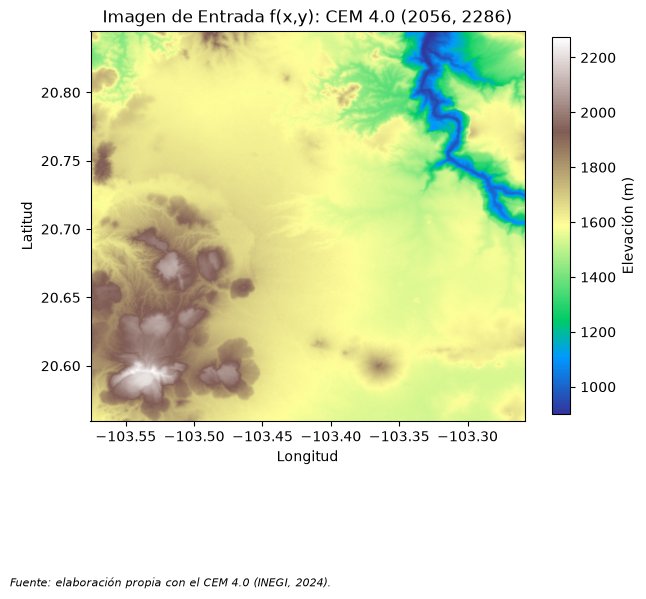

In [1]:
# Código del Paso 1
#Importación de Librerías
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import from_bounds
import matplotlib.pyplot as plt

#Rutas de Entrada y Salida
RAIZ = Path("..")
DEM = RAIZ / "datos/CEM4_GDL_ZAP_recorte.tif"
COL = RAIZ / "datos/colonias_anexo2.csv"
FIG = RAIZ / "resultados/pipeline_cem"
FIG.mkdir(parents=True, exist_ok=True)
FUENTE = "Fuente: elaboración propia con el CEM 4.0 (INEGI, 2024)."

#Carga de las Colonias (puntos del Anexo 2)
colonias = pd.read_csv(COL)
print("Colonias:", len(colonias))

#Carga de la Imagen (solo la ventana de las colonias)
margen = 0.03
oeste, este = colonias.lon.min() - margen, colonias.lon.max() + margen
sur, norte = colonias.lat.min() - margen, colonias.lat.max() + margen

with rasterio.open(DEM) as src:
    ventana = from_bounds(oeste, sur, este, norte, src.transform).round_offsets().round_lengths()
    imagen = src.read(1, window=ventana).astype(np.float64)
    T = src.window_transform(ventana)
    nodata = src.nodata

#Pixeles sin dato se rellenan con la mediana para que la convolución no los propague
sin_dato = imagen == nodata
imagen[sin_dato] = np.median(imagen[~sin_dato])

#Tamaño del pixel en metros (el pixel mide 0.5" x 0.5")
lat0 = (sur + norte) / 2
dx = abs(T.a) * 111320 * np.cos(np.radians(lat0))
dy = abs(T.e) * 110574
extension = [T.c, T.c + T.a * imagen.shape[1], T.f + T.e * imagen.shape[0], T.f]

print("Dimensiones de la imagen:", imagen.shape)
print("Pixeles sin dato:", sin_dato.sum())
print("Tamaño del pixel: %.1f m x %.1f m" % (dx, dy))
print("Elevación: mínima %.0f m, máxima %.0f m" % (imagen.min(), imagen.max()))

plt.figure(figsize=(7, 7))
plt.imshow(imagen, cmap="terrain", extent=extension)
plt.colorbar(shrink=0.7, label="Elevación (m)")
plt.title("Imagen de Entrada f(x,y): CEM 4.0 " + str(imagen.shape))
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.figtext(0.01, -0.02, FUENTE, fontsize=8, style="italic")
plt.savefig(FIG / "paso1_elevacion.png", dpi=200, bbox_inches="tight")
plt.show()

**2.** Definir las funciones de **Convolución** y **Normalización** que serán empleadas:

$$g(x,y)=\sum_{s}\sum_{t}h(s,t)\,f(x-s,\,y-t)$$

* La **Convolución** rota el filtro 180° y rellena los bordes repitiendo el pixel más cercano, para que la imagen de salida conserve las dimensiones de la entrada. A diferencia del Ejercicio 2, acepta filtros de cualquier tamaño (incluso rectangulares, como 1x67).
* La **Normalización** lleva cualquier resultado al intervalo [0, 255] en enteros, y se usa solo para **mostrar** las imágenes; los cálculos se hacen con los valores en metros.

In [2]:
# Código del Paso 2
def convolucion(imagen, filtro):
    #Convolución 2D de una imagen de una banda con un filtro de cualquier tamaño.
    #g(x,y) = sum_s sum_t h(s,t) * f(x-s, y-t)
    kf, kc = filtro.shape
    pf, pc = kf // 2, kc // 2

    #La convolución requiere rotar el filtro 180 grados
    h = np.flipud(np.fliplr(filtro))

    #Relleno de borde: se repite el pixel más cercano
    f_pad = np.pad(imagen, ((pf, pf), (pc, pc)), mode="edge")

    filas, cols = imagen.shape
    g = np.zeros((filas, cols))
    #Cada coeficiente del filtro se multiplica por la ventana desplazada de la imagen
    for s in range(kf):
        for t in range(kc):
            if h[s, t] != 0:
                g += h[s, t] * f_pad[s:s + filas, t:t + cols]
    return g


def normalizacion(imagen_conv):
    #1. Normalización al intervalo [0, 1]
    #2. Escalamiento a 256 valores [0, 255]
    #3. Conversión a valores enteros (uint8)
    minimo, maximo = imagen_conv.min(), imagen_conv.max()
    if maximo == minimo:
        normalizada = np.zeros_like(imagen_conv)
    else:
        normalizada = (imagen_conv - minimo) / (maximo - minimo)
    return np.round(normalizada * 255).astype(np.uint8)

#Prueba rápida con un filtro identidad: la salida debe ser igual a la entrada
identidad = np.zeros((3, 3))
identidad[1, 1] = 1
print("Convolución con identidad igual a la entrada:", np.allclose(convolucion(imagen, identidad), imagen))

Convolución con identidad igual a la entrada: True


**3.** El CEM 4.0 viene de radar (ALOS PALSAR), que deja **ruido** de alta frecuencia: variaciones de uno o dos metros entre pixeles vecinos que no son relieve real. Como la derivada del paso 4 amplifica el ruido, primero se suaviza con un **Filtro Gaussiano** de 5x5 (±2σ) con σ = 1 pixel:

$$G(x,y)=\frac{1}{2\pi\sigma^2}\,e^{-\frac{x^2+y^2}{2\sigma^2}}$$

Se define la **Matriz de Convolución** del filtro, se aplica a la imagen y se muestra un acercamiento de 3 km x 3 km con el ruido eliminado:

Filtro Gaussiano 5x5 (sigma = 1.0):
[[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]
Suma de los coeficientes: 1.0


Cambio medio por el suavizado: 0.42 m


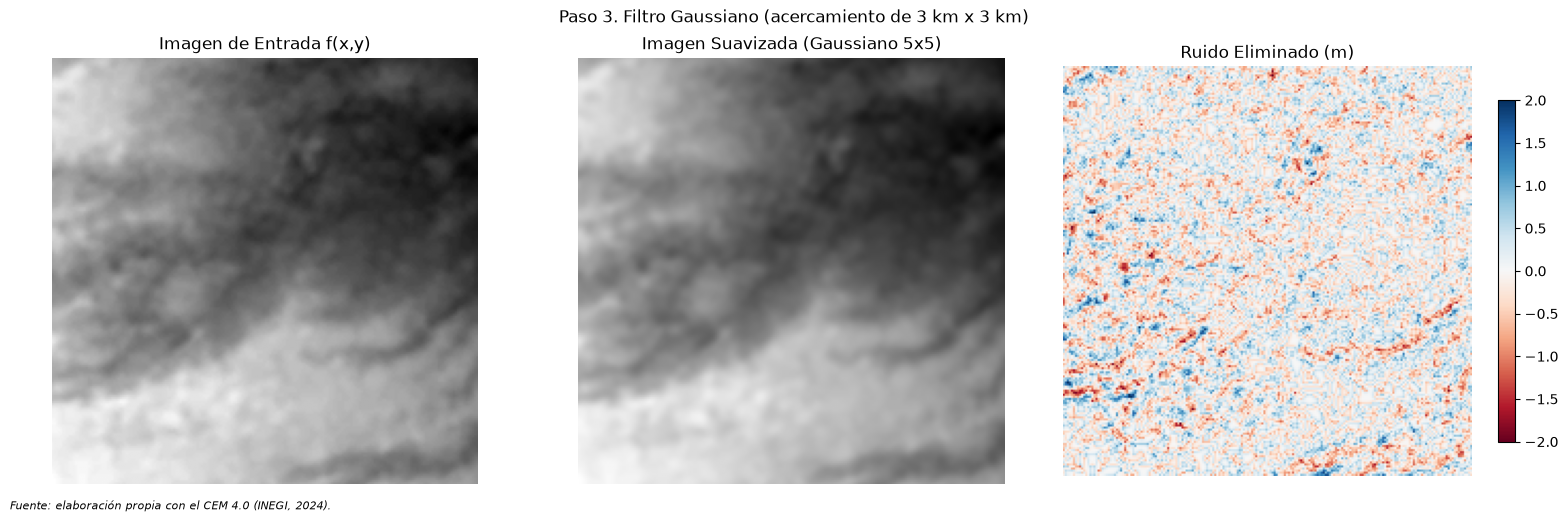

In [3]:
# Código del Paso 3
def filtro_gaussiano(tamano, sigma):
    #Matriz de convolución gaussiana normalizada (sus coeficientes suman 1)
    r = tamano // 2
    y, x = np.mgrid[-r:r + 1, -r:r + 1]
    g = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return g / g.sum()

SIGMA = 1.0
gauss = filtro_gaussiano(5, SIGMA)
print("Filtro Gaussiano 5x5 (sigma = %.1f):" % SIGMA)
print(np.round(gauss, 4))
print("Suma de los coeficientes:", round(gauss.sum(), 6))

imagen_suave = convolucion(imagen, gauss)
print("Cambio medio por el suavizado: %.2f m" % np.abs(imagen - imagen_suave).mean())

#Acercamiento de 200 x 200 pixeles (3 km x 3 km) al centro de la imagen
r0, c0 = imagen.shape[0] // 2 - 100, imagen.shape[1] // 2 - 100
v = (slice(r0, r0 + 200), slice(c0, c0 + 200))

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(normalizacion(imagen[v]), cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Imagen de Entrada f(x,y)")
ax[1].imshow(normalizacion(imagen_suave[v]), cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Imagen Suavizada (Gaussiano 5x5)")
im = ax[2].imshow(imagen[v] - imagen_suave[v], cmap="RdBu", vmin=-2, vmax=2)
ax[2].set_title("Ruido Eliminado (m)")
plt.colorbar(im, ax=ax[2], shrink=0.8)
for a in ax:
    a.axis("off")
plt.suptitle("Paso 3. Filtro Gaussiano (acercamiento de 3 km x 3 km)")
plt.tight_layout()
plt.figtext(0.01, -0.02, FUENTE, fontsize=8, style="italic")
plt.savefig(FIG / "paso3_gaussiano.png", dpi=200, bbox_inches="tight")
plt.show()

**4.** Aplicar los **Filtros Sobel** en *x* y en *y* a la imagen suavizada para obtener el gradiente, y a partir de él la **pendiente** en grados:

$$S_x=\begin{Bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{Bmatrix}\qquad S_y=\begin{Bmatrix}-1&-2&-1\\0&0&0\\1&2&1\end{Bmatrix}$$

La respuesta de Sobel equivale a 8 veces la diferencia de altura entre pixeles vecinos, así que se divide entre $8\,\Delta x$ (o $8\,\Delta y$) para obtener metros de subida por metro recorrido. La pendiente es:

$$\theta=\arctan\sqrt{\left(\tfrac{\partial z}{\partial x}\right)^2+\left(\tfrac{\partial z}{\partial y}\right)^2}$$

Dimensiones de la pendiente: (2056, 2286)
Pendiente: mediana 4.2°, percentil 95 25.1°


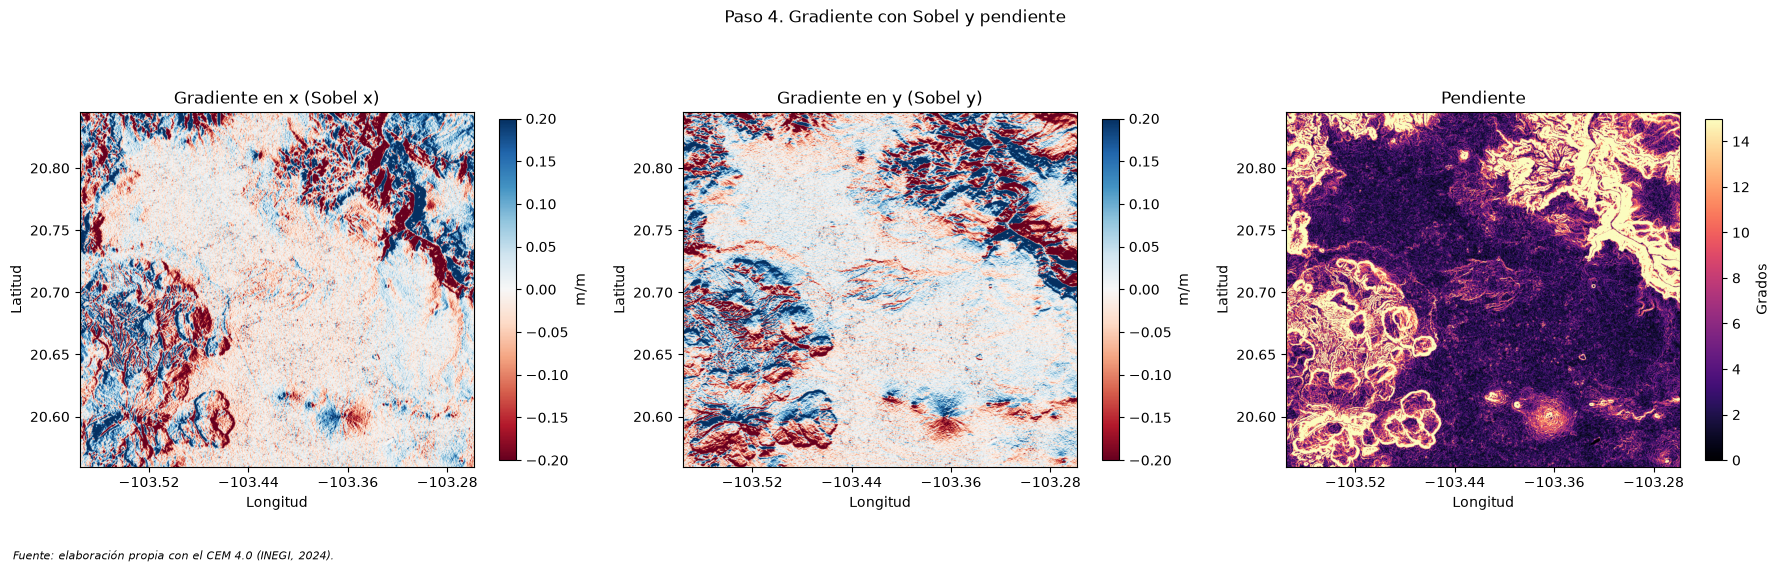

In [4]:
# Código del Paso 4
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=np.float64)
sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]], dtype=np.float64)

#Gradiente en m/m (la convolución rota el filtro, así que se cambia el signo para que
#gx sea positivo cuando la altura sube hacia el este)
gx = -convolucion(imagen_suave, sobel_x) / (8 * dx)
gy = -convolucion(imagen_suave, sobel_y) / (8 * dy)

#Pendiente en grados
pendiente = np.degrees(np.arctan(np.hypot(gx, gy)))

print("Dimensiones de la pendiente:", pendiente.shape)
print("Pendiente: mediana %.1f°, percentil 95 %.1f°" % (np.median(pendiente), np.percentile(pendiente, 95)))

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
im = ax[0].imshow(gx, cmap="RdBu", vmin=-0.2, vmax=0.2, extent=extension)
ax[0].set_title("Gradiente en x (Sobel x)")
plt.colorbar(im, ax=ax[0], shrink=0.7, label="m/m")
im = ax[1].imshow(gy, cmap="RdBu", vmin=-0.2, vmax=0.2, extent=extension)
ax[1].set_title("Gradiente en y (Sobel y)")
plt.colorbar(im, ax=ax[1], shrink=0.7, label="m/m")
im = ax[2].imshow(pendiente, cmap="magma", vmin=0, vmax=15, extent=extension)
ax[2].set_title("Pendiente")
plt.colorbar(im, ax=ax[2], shrink=0.7, label="Grados")
for a in ax:
    a.set_xlabel("Longitud")
    a.set_ylabel("Latitud")
    a.xaxis.set_major_locator(plt.MaxNLocator(4))
plt.suptitle("Paso 4. Gradiente con Sobel y pendiente")
plt.tight_layout()
plt.figtext(0.01, -0.02, FUENTE, fontsize=8, style="italic")
plt.savefig(FIG / "paso4_sobel_pendiente.png", dpi=200, bbox_inches="tight")
plt.show()

**5.** Aplicar un **Filtro Promedio** de 67x67 pixeles (≈ 1 km x 1 km) para obtener la elevación del **entorno**. Es un pasa bajas fuerte que deja solo la forma general del terreno. Al restarlo a la imagen se obtiene la **elevación relativa**, que equivale a un pasa altas:

$$z_{rel}(x,y)=z(x,y)-\frac{1}{67^2}\sum_{s}\sum_{t}z(x-s,\,y-t)$$

Un valor negativo significa que el pixel está **más bajo que su entorno de 1 km**, es decir, que el agua tiende a llegar ahí (**área baja**). Se eligió 1 km porque es del orden del tamaño de una colonia; el issue #8 prueba otros tamaños.

El filtro promedio es **separable**: convolucionar con un filtro de 1x67 y después con uno de 67x1 da el mismo resultado que el filtro de 67x67, pero con 134 multiplicaciones por pixel en lugar de 4,489:

Filtro separable igual al filtro 2D: True
Elevación relativa: percentil 5 = -30.2 m, percentil 95 = 31.9 m
Área baja: 51.8 % de los pixeles


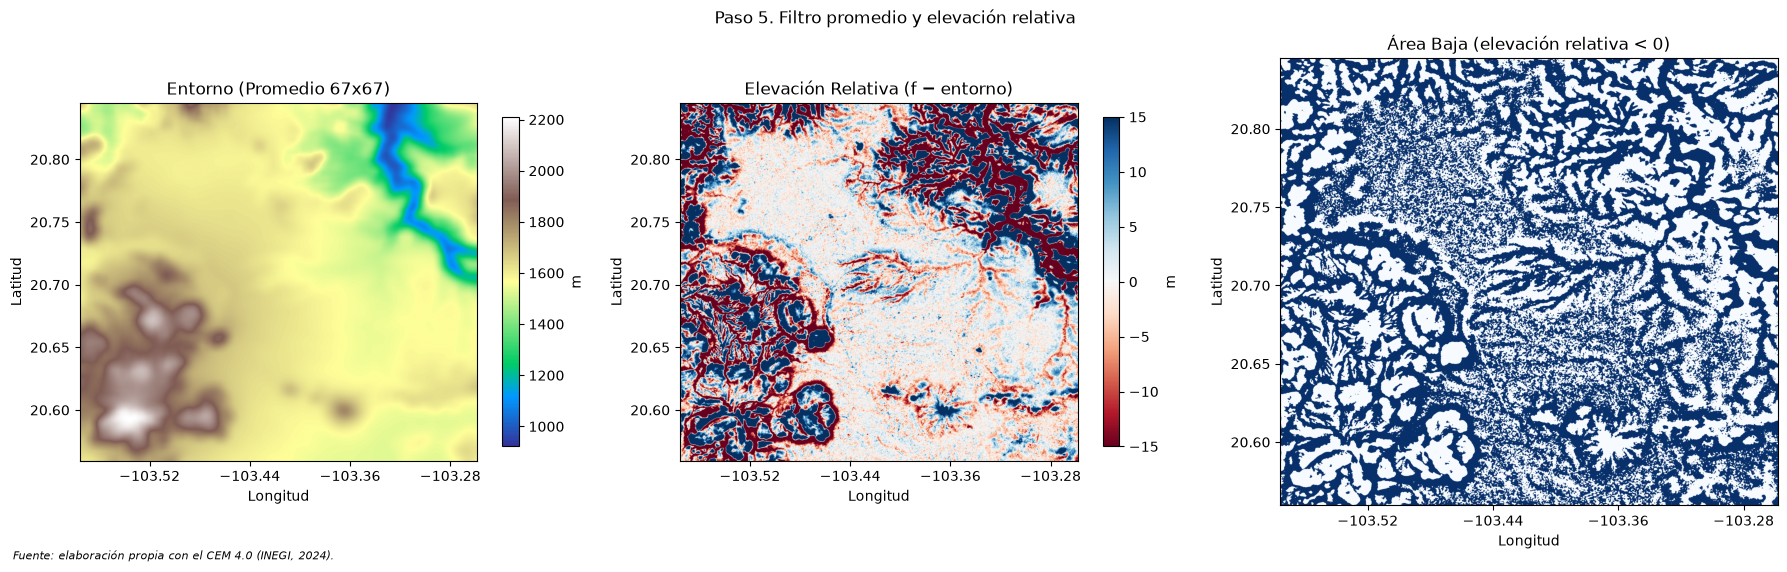

In [5]:
# Código del Paso 5
def filtro_promedio(imagen, n):
    #Filtro promedio n x n aplicado como dos convoluciones 1D (filtro separable)
    fila = np.ones((1, n)) / n
    columna = np.ones((n, 1)) / n
    return convolucion(convolucion(imagen, fila), columna)

VENTANA = 67
entorno = filtro_promedio(imagen, VENTANA)
elevacion_relativa = imagen - entorno
area_baja = elevacion_relativa < 0

#Comprobación de la separabilidad en un recorte pequeño con el filtro 2D completo de 9x9
prueba = imagen[:100, :100]
igual = np.allclose(filtro_promedio(prueba, 9), convolucion(prueba, np.ones((9, 9)) / 81))
print("Filtro separable igual al filtro 2D:", igual)
print("Elevación relativa: percentil 5 = %.1f m, percentil 95 = %.1f m" % tuple(np.percentile(elevacion_relativa, [5, 95])))
print("Área baja: %.1f %% de los pixeles" % (100 * area_baja.mean()))

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
im = ax[0].imshow(entorno, cmap="terrain", extent=extension)
ax[0].set_title("Entorno (Promedio 67x67)")
plt.colorbar(im, ax=ax[0], shrink=0.7, label="m")
im = ax[1].imshow(elevacion_relativa, cmap="RdBu", vmin=-15, vmax=15, extent=extension)
ax[1].set_title("Elevación Relativa (f − entorno)")
plt.colorbar(im, ax=ax[1], shrink=0.7, label="m")
ax[2].imshow(area_baja, cmap="Blues", extent=extension)
ax[2].set_title("Área Baja (elevación relativa < 0)")
for a in ax:
    a.set_xlabel("Longitud")
    a.set_ylabel("Latitud")
    a.xaxis.set_major_locator(plt.MaxNLocator(4))
plt.suptitle("Paso 5. Filtro promedio y elevación relativa")
plt.tight_layout()
plt.figtext(0.01, -0.02, FUENTE, fontsize=8, style="italic")
plt.savefig(FIG / "paso5_elevacion_relativa.png", dpi=200, bbox_inches="tight")
plt.show()

**6.** Calcular las **Estadísticas por Colonia**. No se tienen los polígonos de las colonias, así que cada colonia es un punto del Anexo 2 y se toman los pixeles a 500 m o menos de él. En cada círculo se calcula:

* `elev_media`: elevación media (m).
* `pendiente_media`: pendiente media (°).
* `pct_area_baja`: % de pixeles con elevación relativa negativa.

Como **prueba de sentido** se revisan dos colonias conocidas: **Las Conchas**, en la zona baja del sur de Guadalajara y una de las 20 colonias con más inundaciones según González et al. (2025), debe salir plana y con mucha área baja; **Volcán del Colli**, en las faldas del cerro del Colli, debe salir con mucha pendiente:

In [6]:
# Código del Paso 6
RADIO_M = 500

def estadisticas_colonias(colonias, imagen, pendiente, elevacion_relativa, radio_m):
    #Máscara circular de radio_m metros (el pixel no es cuadrado: dx != dy)
    ry, rx = int(np.ceil(radio_m / dy)), int(np.ceil(radio_m / dx))
    yy, xx = np.mgrid[-ry:ry + 1, -rx:rx + 1]
    disco = (xx * dx)**2 + (yy * dy)**2 <= radio_m**2

    resultado = []
    for lon, lat in zip(colonias.lon, colonias.lat):
        #Coordenadas geográficas -> fila y columna del pixel
        c, r = ~T * (lon, lat)
        c, r = int(c), int(r)
        sl = (slice(r - ry, r + ry + 1), slice(c - rx, c + rx + 1))
        resultado.append([imagen[sl][disco].mean(),
                          pendiente[sl][disco].mean(),
                          100 * (elevacion_relativa[sl][disco] < 0).mean()])
    resultado = pd.DataFrame(resultado, columns=["elev_media", "pendiente_media", "pct_area_baja"]).round(2)
    return colonias.drop(columns=resultado.columns, errors="ignore").reset_index(drop=True).join(resultado)

colonias = estadisticas_colonias(colonias, imagen, pendiente, elevacion_relativa, RADIO_M)
print("Dimensiones de la tabla:", colonias.shape)
display(colonias[["elev_media", "pendiente_media", "pct_area_baja"]].describe().round(2))

#Prueba de sentido
display(colonias.loc[colonias.colonia.isin(["Las Conchas", "Volcán del Colli"]),
                     ["colonia", "municipio", "elev_media", "pendiente_media", "pct_area_baja", "grupo_inundacion"]])

Dimensiones de la tabla: (605, 18)


,elev_media,pendiente_media,pct_area_baja
count,605.00,605.00,605.00
mean,1592.19,3.50,51.90
std,51.96,1.67,16.15
min,1436.21,1.69,1.98
25%,1555.98,2.55,42.25
50%,1593.18,2.96,52.50
75%,1625.30,3.77,62.16
max,1836.43,14.31,91.87


,colonia,municipio,elev_media,pendiente_media,pct_area_baja,grupo_inundacion
97,Las Conchas,Guadalajara,1543.57,2.20,72.66,alta
598,Volcán del Colli,Zapopan,1749.66,12.36,70.43,baja


**7.** Comparar la topografía entre los grupos de **alta** y **baja** inundación (clasificación del Mapa Único de Inundaciones). Para saber si la diferencia de medias puede deberse al azar se usa una **Prueba de Permutación**: se revuelven 10,000 veces las etiquetas alta/baja y se cuenta en cuántas la diferencia es igual o mayor a la observada (p de dos colas). Al final se guarda la tabla por colonia:

,elev_media,pendiente_media,pct_area_baja
grupo_inundacion,,,
alta,1576.71,3.24,55.79
baja,1601.36,3.65,49.59


pendiente_media: diferencia alta - baja = -0.41 | p = 0.0023


pct_area_baja: diferencia alta - baja = 6.20 | p = 0.0000


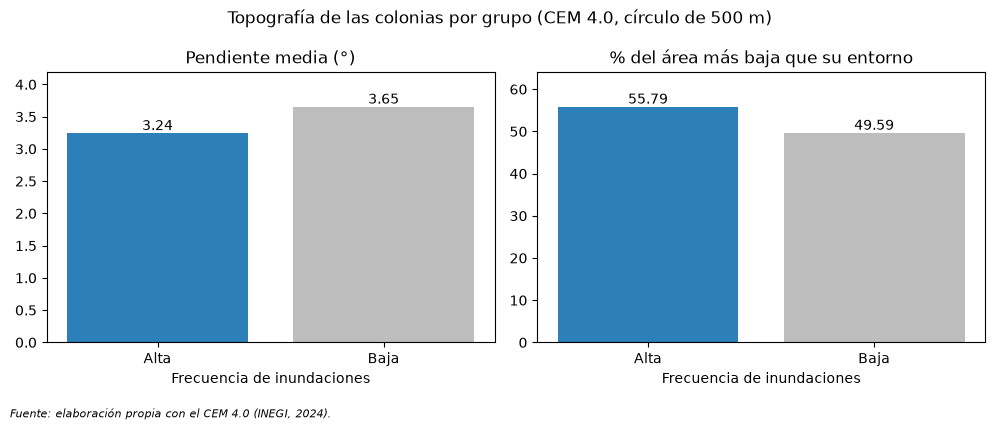

Tabla guardada en ..\resultados\colonias_topografia.csv


In [7]:
# Código del Paso 7
def prueba_permutacion(valores, es_alta, n=10000, semilla=7):
    #Diferencia de medias (alta - baja) y p de dos colas por permutación de etiquetas
    rng = np.random.default_rng(semilla)
    y = np.asarray(valores, dtype=float)
    m = np.asarray(es_alta, dtype=bool)
    observada = y[m].mean() - y[~m].mean()
    permutadas = np.zeros(n)
    for i in range(n):
        k = rng.permutation(m)
        permutadas[i] = y[k].mean() - y[~k].mean()
    return observada, (np.abs(permutadas) >= abs(observada)).mean()

es_alta = colonias.grupo_inundacion == "alta"
grupos = colonias.groupby("grupo_inundacion")[["elev_media", "pendiente_media", "pct_area_baja"]].mean().round(2)
display(grupos)

for variable in ["pendiente_media", "pct_area_baja"]:
    dif, p = prueba_permutacion(colonias[variable], es_alta)
    print("%s: diferencia alta - baja = %.2f | p = %.4f" % (variable, dif, p))

#Gráfica de barras por grupo
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
titulos = ["Pendiente media (°)", "% del área más baja que su entorno"]
for a, variable, titulo in zip(ax, ["pendiente_media", "pct_area_baja"], titulos):
    valores = grupos.loc[["alta", "baja"], variable]
    a.bar(["Alta", "Baja"], valores, color=["#2c7fb8", "#bdbdbd"])
    for i, val in enumerate(valores):
        a.text(i, val, "%.2f" % val, ha="center", va="bottom")
    a.set_ylim(0, valores.max() * 1.15)
    a.set_title(titulo)
    a.set_xlabel("Frecuencia de inundaciones")
plt.suptitle("Topografía de las colonias por grupo (CEM 4.0, círculo de 500 m)")
plt.tight_layout()
plt.figtext(0.01, -0.04, FUENTE, fontsize=8, style="italic")
plt.savefig(FIG / "paso7_grupos.png", dpi=200, bbox_inches="tight")
plt.show()

#Se guarda la tabla por colonia
salida = RAIZ / "resultados/colonias_topografia.csv"
colonias.to_csv(salida, index=False, encoding="utf-8-sig")
print("Tabla guardada en", salida)

#### Limitaciones:
* El CEM 4.0 se generó con radar de 2006–2011: no refleja rellenos o cortes posteriores, y en zonas muy construidas puede incluir parte de la altura de los edificios.
* Con 15 m de resolución se captan lomas y hondonadas, pero no los desniveles de una sola calle.
* En las laderas el `pct_area_baja` también sale alto, porque el promedio de 1 km incluye la parte alta del cerro (por ejemplo, Volcán del Colli). Por eso el área baja se lee junto con la pendiente: una colonia propensa a encharcarse tiene **mucha área baja y poca pendiente**.
* El círculo de 500 m es una aproximación a la colonia; colonias grandes o alargadas quedan mal representadas y los círculos de colonias vecinas se traslapan.

#### Reutilizar este notebook (issues #7 y #8):
En otro notebook de esta carpeta, `%run ./01_pipeline_CEM.ipynb` carga todas las variables y funciones. Para cambiar el tamaño del filtro o el radio:
```python
entorno = filtro_promedio(imagen, 133)
tabla = estadisticas_colonias(pd.read_csv(COL), imagen, pendiente, imagen - entorno, 800)
```